# Caso 05: RutaSabor — Cocina Fantasma: ¿Dónde Está el Margen?
## Día 5: Que se Entienda y Cambie Algo (Gráficos Ejecutivos y Decisión de Inversión)

**El propósito del Día 5:**
*"El hallazgo no vale nada si no cambia una decisión"*.
Hoy convertimos toda la semana analítica (limpieza forense, definición de margen, comisiones por canal, incidencias y control por cocina) en **4 gráficos ejecutivos con Seaborn** y un documento de decisión (**`ONE_PAGER.md`**) para la reunión de las 12:00 con Clara Montero (CEO), Gonzalo Prats (Expansión) y Bea Solís (Operaciones).

**Los Cuatro Principios del Gráfico que Decide:**
1. **Una sola idea por gráfico:** Menos es más; nada de gráficos recargados que confunden a dirección.
2. **Orden deliberado:** Ordenar por la métrica que importa (el margen o la cuota de contribución), no alfabéticamente.
3. **Color con significado funcional:** Azul para facturación/GMV, verde para margen/contribución real, rojo/naranja para pérdidas o costes.
4. **El título dice la conclusión:** El titular es la decisión, no una mera etiqueta técnica.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import duckdb
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

CLEAN_DIR = os.path.join('data', 'clean')
REPORTS_DIR = 'reports'
os.makedirs(REPORTS_DIR, exist_ok=True)

# Estilo visual corporativo ejecutivo
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

con = duckdb.connect()
con.execute(f"CREATE VIEW pedidos AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'pedidos.parquet')}'")
con.execute(f"CREATE VIEW lineas_pedido AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'lineas_pedido.parquet')}'")
con.execute(f"CREATE VIEW productos AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'productos.parquet')}'")
con.execute(f"CREATE VIEW marcas AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'marcas.parquet')}'")
con.execute(f"CREATE VIEW canales AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'canales.parquet')}'")
con.execute(f"CREATE VIEW cocinas AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'cocinas.parquet')}'")
con.execute(f"CREATE VIEW incidencias AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'incidencias.parquet')}'")

print("Vistas DuckDB conectadas y listas.")


Vistas DuckDB conectadas y listas.


### 1. Construcción de la Tabla Maestra de Métricas
Calculamos todas las métricas acumuladas de la semana en una sola consulta con DuckDB:
* Pedidos totales y % sobre el total
* Facturación Bruta (GMV) y % GMV
* Ticket medio
* Desglose de costes unitarios (ingredientes, comisión e incidencias)
* Margen de Contribución por pedido
* Margen de Contribución total y % Cuota de Contribución


In [2]:
query_maestra = """
WITH ingredientes AS (
    SELECT 
        lp.pedido_id,
        SUM(lp.cantidad * pr.coste_ingredientes) AS coste_ingredientes
    FROM lineas_pedido lp
    JOIN productos pr ON lp.producto_id = pr.producto_id
    GROUP BY lp.pedido_id
),
incidencias_agg AS (
    SELECT 
        pedido_id,
        SUM(importe_compensacion) AS coste_incidencia
    FROM incidencias
    GROUP BY pedido_id
)
SELECT 
    m.nombre AS marca,
    COUNT(*) AS total_pedidos,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS cuota_pedidos_pct,
    ROUND(SUM(p.importe_cobrado), 2) AS gmv_total_eur,
    ROUND(SUM(p.importe_cobrado) * 100.0 / SUM(SUM(p.importe_cobrado)) OVER (), 2) AS cuota_gmv_pct,
    ROUND(AVG(p.importe_cobrado), 2) AS ticket_medio_eur,
    ROUND(AVG(ing.coste_ingredientes), 2) AS coste_ingredientes_eur,
    ROUND(AVG(p.importe_cobrado * can.comision_pct), 2) AS comision_canal_eur,
    ROUND(AVG(COALESCE(inc.coste_incidencia, 0)), 2) AS coste_incidencias_eur,
    ROUND(AVG(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)), 2) AS margen_contribucion_medio_eur,
    ROUND(SUM(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)), 2) AS margen_contribucion_total_eur,
    ROUND(SUM(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) * 100.0 / 
          SUM(SUM(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0))) OVER (), 2) AS cuota_contribucion_pct
FROM pedidos p
JOIN marcas m ON p.marca_id = m.marca_id
JOIN canales can ON p.canal_id = can.canal_id
JOIN ingredientes ing ON p.pedido_id = ing.pedido_id
LEFT JOIN incidencias_agg inc ON p.pedido_id = inc.pedido_id
GROUP BY m.nombre
ORDER BY margen_contribucion_medio_eur DESC;
"""

df_maestra = con.execute(query_maestra).df()
print("=== TABLA MAESTRA DE DECISIÓN ===")
display(df_maestra)


=== TABLA MAESTRA DE DECISIÓN ===


,marca,total_pedidos,cuota_pedidos_pct,gmv_total_eur,cuota_gmv_pct,ticket_medio_eur,coste_ingredientes_eur,comision_canal_eur,coste_incidencias_eur,margen_contribucion_medio_eur,margen_contribucion_total_eur,cuota_contribucion_pct
0,Poke Break,21001,14.00,332399.81,19.16,15.83,9.10,3.01,0.14,3.59,75340.27,27.90
1,Pizza Nostra,25428,16.95,346104.43,19.95,13.61,7.24,3.42,0.28,2.67,67934.80,25.16
2,Wok Express,25496,17.00,292582.07,16.87,11.48,6.09,3.02,0.23,2.14,54559.98,20.21
3,Dulce Antojo,27097,18.06,176489.03,10.17,6.51,3.37,1.56,0.18,1.41,38141.41,14.13
4,La Brasa Burger,50978,33.99,587264.21,33.85,11.52,7.06,3.26,0.53,0.67,34048.66,12.61


### Gráfico 1: El Contraste que Desmonta el Espejismo (GMV vs Contribución)
**Propósito:** Demostrar de un solo vistazo por qué facturar mucho no es ganar dinero.
Enfrenta marca a marca lo que factura (% GMV en azul) con lo que aporta a la caja (% Contribución en verde).


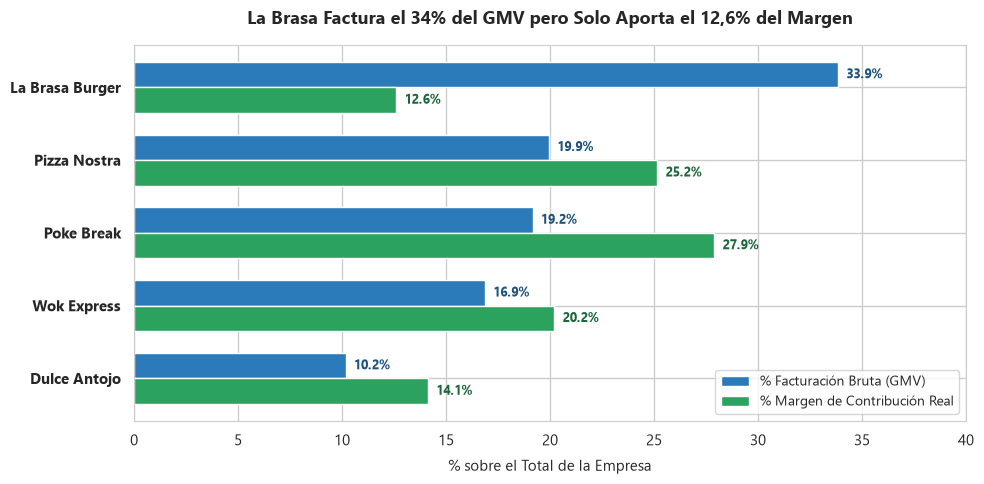

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

df_g1 = df_maestra.sort_values('cuota_gmv_pct', ascending=True)
y = np.arange(len(df_g1))
h = 0.35

ax.barh(y + h/2, df_g1['cuota_gmv_pct'], h, label='% Facturación Bruta (GMV)', color='#2b7bba')
ax.barh(y - h/2, df_g1['cuota_contribucion_pct'], h, label='% Margen de Contribución Real', color='#2ca25f')

ax.set_yticks(y)
ax.set_yticklabels(df_g1['marca'], fontsize=11, fontweight='bold')
ax.set_xlabel('% sobre el Total de la Empresa', fontsize=11, labelpad=8)
ax.set_title('La Brasa Factura el 34% del GMV pero Solo Aporta el 12,6% del Margen', fontsize=13, fontweight='bold', pad=15)
ax.set_xlim(0, 40)
ax.legend(frameon=True, facecolor='white', loc='lower right', fontsize=10)

for i, row in enumerate(df_g1.itertuples()):
    ax.text(row.cuota_gmv_pct + 0.4, i + h/2, f"{row.cuota_gmv_pct:.1f}%", va='center', fontsize=9.5, color='#1c527c', fontweight='bold')
    ax.text(row.cuota_contribucion_pct + 0.4, i - h/2, f"{row.cuota_contribucion_pct:.1f}%", va='center', fontsize=9.5, color='#1b663b', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_05_grafico_1_gmv_vs_contribucion.png'), dpi=300)
plt.show()


### Gráfico 2: Margen de Contribución por Pedido (Calidad Económica)
**Propósito:** Comparar el dinero neto que deja cada pedido de cada marca una vez pagados todos sus costes variables.


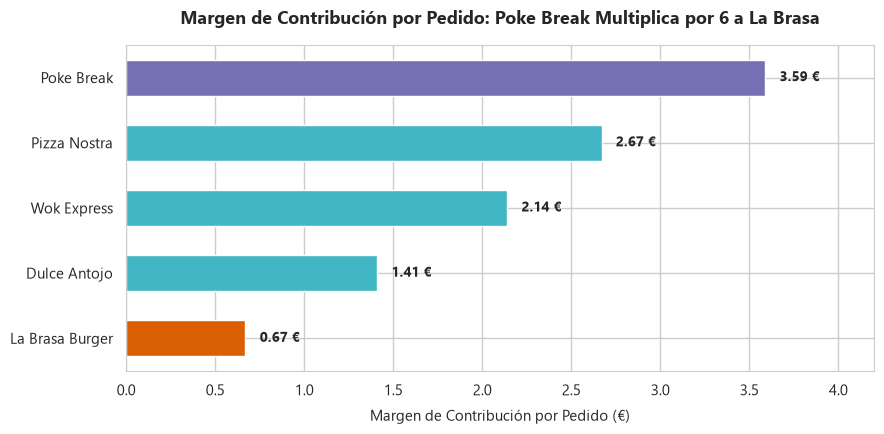

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))

df_g2 = df_maestra.sort_values('margen_contribucion_medio_eur', ascending=True)
colores_g2 = ['#d95f02' if m == 'La Brasa Burger' else '#7570b3' if m == 'Poke Break' else '#41b6c4' for m in df_g2['marca']]

bars = ax.barh(df_g2['marca'], df_g2['margen_contribucion_medio_eur'], color=colores_g2, height=0.55)
ax.set_title('Margen de Contribución por Pedido: Poke Break Multiplica por 6 a La Brasa', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Margen de Contribución por Pedido (€)', fontsize=11, labelpad=8)
ax.set_xlim(0, 4.2)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.08, bar.get_y() + bar.get_height()/2, f"{w:.2f} €", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_05_grafico_2_margen_por_pedido.png'), dpi=300)
plt.show()


### Gráfico 3: La Cascada de La Brasa (El Mecanismo de la Pérdida)
**Propósito:** Demostrar por qué La Brasa se desangra paso a paso. De 11,52 € que paga el cliente, solo quedan 0,60 € en caja.


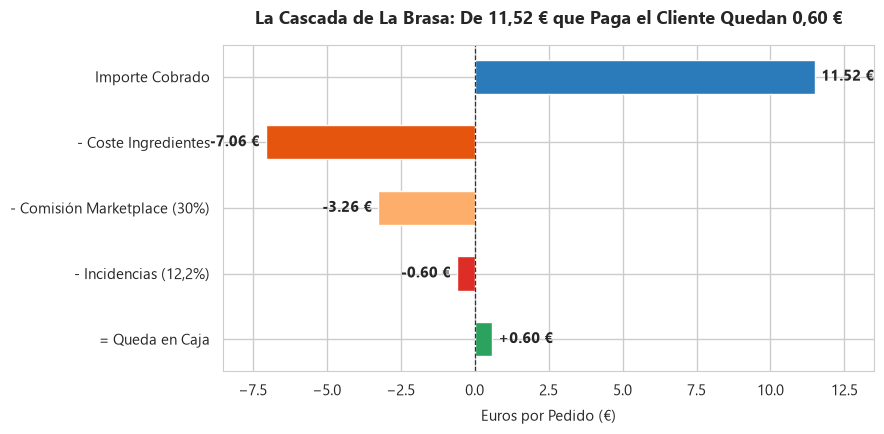

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))

rubros = ['Importe Cobrado', '- Coste Ingredientes', '- Comisión Marketplace (30%)', '- Incidencias (12,2%)', '= Queda en Caja']
montos = [11.52, -7.06, -3.26, -0.60, 0.60]
colores_cascada = ['#2b7bba', '#e6550d', '#fdae6b', '#de2d26', '#2ca25f']

bars = ax.barh(rubros[::-1], montos[::-1], color=colores_cascada[::-1], height=0.52)
ax.set_title('La Cascada de La Brasa: De 11,52 € que Paga el Cliente Quedan 0,60 €', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Euros por Pedido (€)', fontsize=11, labelpad=8)
ax.axvline(0, color='#333333', linewidth=0.9, linestyle='--')
ax.set_xlim(-8.5, 13.5)

for i, val in enumerate(montos[::-1]):
    align = 'left' if val >= 0 else 'right'
    offset = 0.2 if val >= 0 else -0.2
    txt = f"{val:+.2f} €" if i != 4 else f"{val:.2f} €"
    ax.text(val + offset, i, txt, va='center', ha=align, fontsize=10.5, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_05_grafico_3_cascada_la_brasa.png'), dpi=300)
plt.show()


### Gráfico 4: El Control de Robustez por Cocina (Descartando a Vallecas)
**Propósito:** Blindar la conclusión frente a Bea Solís y Gonzalo. La brecha de ~3 € entre Poke Break y La Brasa es constante en las 10 cocinas.


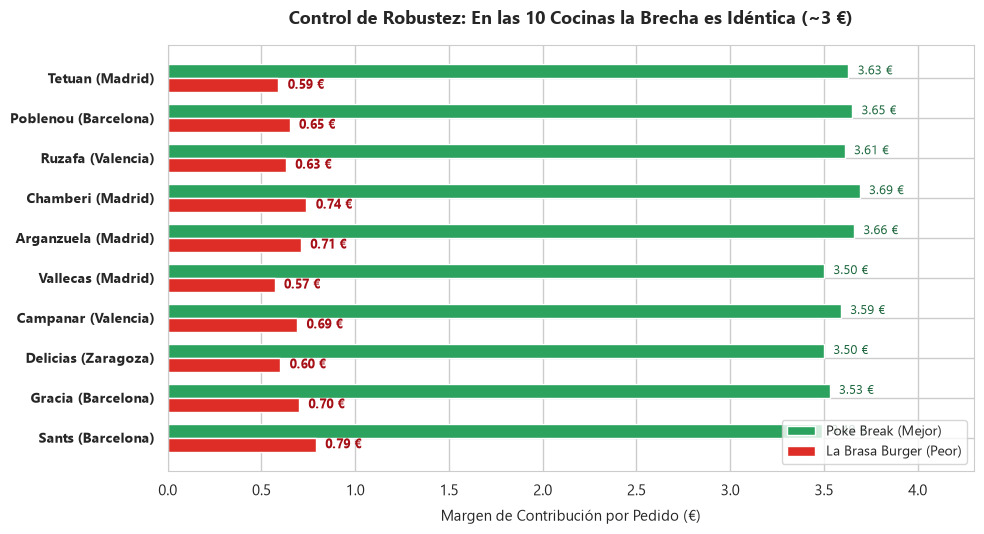

In [6]:
query_control_cocinas = """
WITH ingredientes AS (
    SELECT 
        lp.pedido_id,
        SUM(lp.cantidad * pr.coste_ingredientes) AS coste_ingredientes
    FROM lineas_pedido lp
    JOIN productos pr ON lp.producto_id = pr.producto_id
    GROUP BY lp.pedido_id
),
incidencias_agg AS (
    SELECT 
        pedido_id,
        SUM(importe_compensacion) AS coste_incidencia
    FROM incidencias
    GROUP BY pedido_id
)
SELECT 
    c.nombre AS cocina,
    c.ciudad,
    ROUND(AVG(CASE WHEN m.nombre = 'La Brasa Burger' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END), 2) AS la_brasa_eur,
    ROUND(AVG(CASE WHEN m.nombre = 'Poke Break' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END), 2) AS poke_break_eur,
    ROUND(AVG(CASE WHEN m.nombre = 'Poke Break' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END) -
          AVG(CASE WHEN m.nombre = 'La Brasa Burger' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END), 2) AS brecha_eur
FROM pedidos p
JOIN cocinas c ON p.cocina_id = c.cocina_id
JOIN marcas m ON p.marca_id = m.marca_id
JOIN canales can ON p.canal_id = can.canal_id
JOIN ingredientes ing ON p.pedido_id = ing.pedido_id
LEFT JOIN incidencias_agg inc ON p.pedido_id = inc.pedido_id
GROUP BY c.nombre, c.ciudad
ORDER BY brecha_eur DESC;
"""

df_control = con.execute(query_control_cocinas).df()

fig, ax = plt.subplots(figsize=(10, 5.5))
df_c_plot = df_control.sort_values('brecha_eur', ascending=True)

y = np.arange(len(df_c_plot))
h = 0.35

ax.barh(y + h/2, df_c_plot['poke_break_eur'], h, label='Poke Break (Mejor)', color='#2ca25f')
ax.barh(y - h/2, df_c_plot['la_brasa_eur'], h, label='La Brasa Burger (Peor)', color='#de2d26')

ax.set_yticks(y)
ax.set_yticklabels([f"{r.cocina} ({r.ciudad})" for r in df_c_plot.itertuples()], fontsize=10, fontweight='bold')
ax.set_xlabel('Margen de Contribución por Pedido (€)', fontsize=11, labelpad=8)
ax.set_title('Control de Robustez: En las 10 Cocinas la Brecha es Idéntica (~3 €)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlim(0, 4.3)
ax.legend(frameon=True, facecolor='white', loc='lower right', fontsize=10)

for i, row in enumerate(df_c_plot.itertuples()):
    ax.text(row.poke_break_eur + 0.05, i + h/2, f"{row.poke_break_eur:.2f} €", va='center', fontsize=9, color='#1b663b')
    ax.text(row.la_brasa_eur + 0.05, i - h/2, f"{row.la_brasa_eur:.2f} €", va='center', fontsize=9, color='#a50f15', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_05_grafico_4_control_cocinas.png'), dpi=300)
plt.show()


### Conclusión del Caso 05:
1. **El Titular en una sola frase:**
   * *"La Brasa factura el 34% del GMV pero solo aporta el 12,6% del margen; escalarla es multiplicar volumen de trabajo sin rentabilidad"*.
2. **Impacto de Negocio:**
   * Frenamos una inversión de cientos de miles de euros destinada a clonar una marca con margen raquítico (0,60 €/pedido).
   * Redirigimos el presupuesto de expansión hacia **Poke Break** (3,56 €/pedido y 27,9% del margen) y el empuje de la **App propia** (6% de comisión).
